# 4. Convert manual gradient descent calculations into Python code


## Step 1: Import Libraries

In [1]:
import numpy as np
from scipy.optimize import approx_fprime
import matplotlib.pyplot as plt

## Step 2: Define the Dataset

In [2]:
X = np.array([[1, 3],
              [4, 10]], dtype=float)
target = np.array([5, 6], dtype=float)

m = np.array([-1.0, 2.0])
b = 1.0
lr = 0.01
n = X.shape[0]
n_iterations = 3

## Step 3: Prediction Function

In [3]:
def predict(m, b, X):
    """y_hat = X . m + b   (matrix multiplication, not element-by-element)."""
    return X.dot(m) + b

def cost_J(params, X, target):
    """MSE cost: J = (1/n) * sum((y_hat - target)^2)."""
    m_ = params[:2]
    b_ = params[2]
    y_hat = predict(m_, b_, X)
    error = y_hat - target
    return np.mean(error ** 2)

In [4]:
def analytical_gradient(m, b, X, target):
    y_hat = predict(m, b, X)
    error = y_hat - target
    grad_m = (2 / n) * X.T.dot(error)
    grad_b = (2 / n) * np.sum(error)
    return grad_m, grad_b, error, y_hat

In [5]:
def scipy_gradient(m, b, X, target, epsilon=1e-6):
    params = np.array([m[0], m[1], b])
    grad = approx_fprime(params, cost_J, epsilon, X, target)
    return grad[:2], grad[2]

In [6]:
history_m = [m.copy()]
history_b = [b]
history_error = []

print("=" * 70)
print("GRADIENT DESCENT - PART 4 (Python reproduction of manual Part 3)")
print("=" * 70)

for i in range(1, n_iterations + 1):
    print(f"\n--- Iteration {i} ---")
    print(f"Current m = {m}, b = {b}")

    # Step 1: Predict
    y_hat = predict(m, b, X)
    print(f"Prediction y_hat = X . m + b = {y_hat}")

    # Step 2: Error
    error = y_hat - target
    print(f"Error e = y_hat - target = {error}")

    # Step 3: MSE cost (for the error-vs-iteration plot)
    mse = np.mean(error ** 2)
    history_error.append(mse)
    print(f"MSE cost J = {mse:.4f}")

    # Step 4: Analytical gradient
    grad_m, grad_b, _, _ = analytical_gradient(m, b, X, target)
    print(f"Analytical gradient  -> grad_m = {grad_m}, grad_b = {grad_b}")

    # Step 5: SciPy numerical gradient (sanity check against analytical one)
    grad_m_scipy, grad_b_scipy = scipy_gradient(m, b, X, target)
    print(f"SciPy numerical grad -> grad_m = {np.round(grad_m_scipy, 4)}, "
          f"grad_b = {grad_b_scipy:.4f}  (should match analytical)")

    # Step 6: Update m and b
    m = m - lr * grad_m
    b = b - lr * grad_b
    print(f"Updated  -> m = {np.round(m, 4)}, b = {round(b, 4)}")

    history_m.append(m.copy())
    history_b.append(b)

# Final MSE after the last update (for a complete error curve)
final_pred = predict(m, b, X)
final_error = final_pred - target
history_error.append(np.mean(final_error ** 2))

print("\n" + "=" * 70)
print(f"FINAL PARAMETERS after {n_iterations} iterations:")
print(f"m = {np.round(m, 4)}")
print(f"b = {round(b, 4)}")
print(f"Final predictions y_hat = {np.round(final_pred, 4)}")
print("=" * 70)

history_m = np.array(history_m)

GRADIENT DESCENT - PART 4 (Python reproduction of manual Part 3)

--- Iteration 1 ---
Current m = [-1.  2.], b = 1.0
Prediction y_hat = X . m + b = [ 6. 17.]
Error e = y_hat - target = [ 1. 11.]
MSE cost J = 61.0000
Analytical gradient  -> grad_m = [ 45. 113.], grad_b = 12.0
SciPy numerical grad -> grad_m = [ 45.     113.0001], grad_b = 12.0000  (should match analytical)
Updated  -> m = [-1.45  0.87], b = 0.88

--- Iteration 2 ---
Current m = [-1.45  0.87], b = 0.88
Prediction y_hat = X . m + b = [2.04 3.78]
Error e = y_hat - target = [-2.96 -2.22]
MSE cost J = 6.8450
Analytical gradient  -> grad_m = [-11.84 -31.08], grad_b = -5.1800000000000015
SciPy numerical grad -> grad_m = [-11.84   -31.0799], grad_b = -5.1800  (should match analytical)
Updated  -> m = [-1.3316  1.1808], b = 0.9318

--- Iteration 3 ---
Current m = [-1.3316  1.1808], b = 0.9318
Prediction y_hat = X . m + b = [3.1426 7.4134]
Error e = y_hat - target = [-1.8574  1.4134]
MSE cost J = 2.7238
Analytical gradient  -> gra

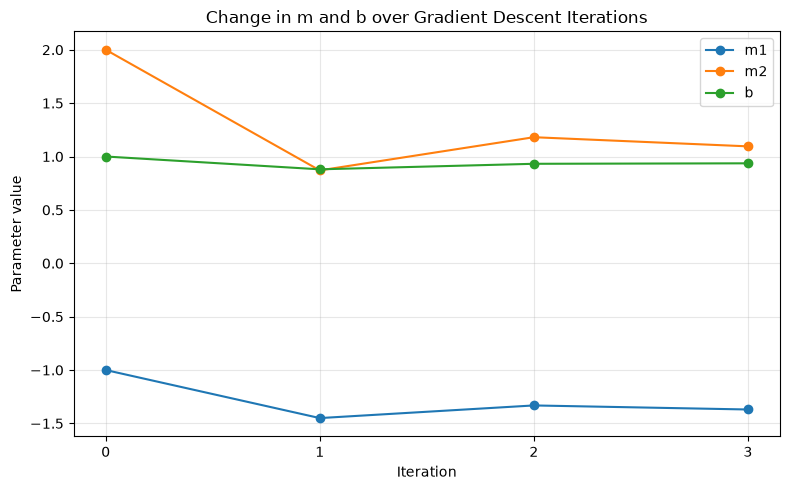

In [7]:
iterations = np.arange(len(history_b))   # 0, 1, 2, ..., n_iterations
plt.figure(figsize=(8, 5))
plt.plot(iterations, history_m[:, 0], marker='o', label='m1')
plt.plot(iterations, history_m[:, 1], marker='o', label='m2')
plt.plot(iterations, history_b, marker='o', label='b')
plt.xlabel('Iteration')
plt.ylabel('Parameter value')
plt.title('Change in m and b over Gradient Descent Iterations')
plt.xticks(iterations)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('params_over_iterations.png', dpi=150)
plt.show()
plt.close()

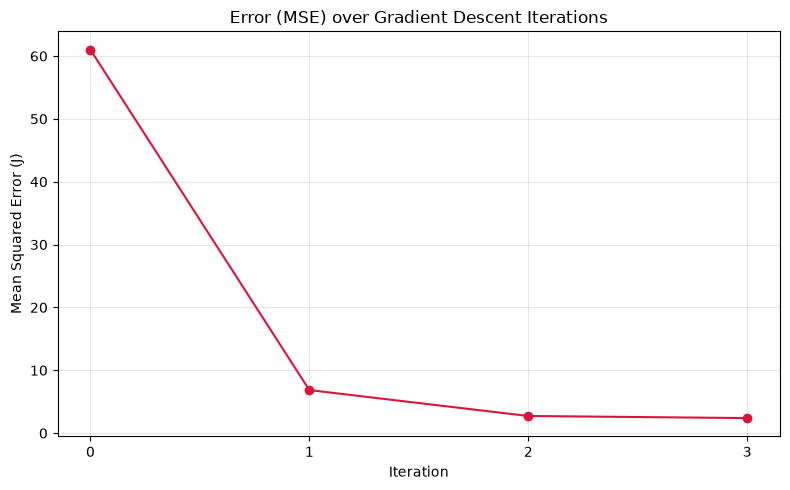

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(iterations, history_error, marker='o', color='crimson')
plt.xlabel('Iteration')
plt.ylabel('Mean Squared Error (J)')
plt.title('Error (MSE) over Gradient Descent Iterations')
plt.xticks(iterations)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('error_over_iterations.png', dpi=150)
plt.show()
plt.close()